# Análisis Exploratorio de Datos (EDA) — Netflix

**Objetivo:** diagnosticar la calidad del dataset original antes de construir la capa **silver**.
Cada hallazgo de este notebook se traduce en una regla de limpieza en `config/config.yaml`.

| Sección | Qué responde |
|---|---|
| 1. Carga | ¿Qué archivo analizamos? |
| 2. Dimensiones | ¿Cuántas filas y columnas tiene? |
| 3. Tipos de datos | ¿Pandas reconoce bien números, fechas y textos? ¿Hay columnas que descomponer? |
| 4. Nulos | ¿Cuántos faltan por columna y en qué %? (reales y ocultos) |
| 5. Duplicados y únicos | ¿Hay registros repetidos? ¿Cuál es la cardinalidad? |
| 6. Estadística descriptiva | ¿Cómo se resumen las variables? |
| 7. Visualizaciones | Distribuciones, outliers, categorías, correlaciones, tiempo y análisis de Netflix |
| 8. Hallazgos → reglas | ¿Qué limpiamos en silver? |
| 9. Antes vs. después | ¿Funcionó la limpieza? |

> Las secciones 1–6 y 8–9 son genéricas: funcionan con cualquier dataset cambiando `source.file_path`
> en `config/config.yaml`. La sección 7.6 es específica de Netflix.

## 0. Configuración del entorno

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Raíz del proyecto 
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.utils import load_config, resolve_path, strip_accents, to_snake_case

config = load_config()

# Estilo de gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
COLOR = "#2E6FBA"          # un solo color para gráficos de una serie
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: c:\Users\jeant\Downloads\Etl\proyecto_pipeline\proyecto_pipeline


## 1. Carga de datos
Leemos el archivo **original** con la inferencia de tipos por defecto de pandas
(así vemos el dato como llega, con sus problemas).

In [2]:
src_cfg = config["source"]
file_path = resolve_path(src_cfg["file_path"])

if file_path.suffix.lower() == ".csv":
    df = pd.read_csv(file_path, sep=src_cfg.get("csv_separator", ","), encoding=src_cfg.get("encoding", "utf-8"))
else:
    df = pd.read_excel(file_path, sheet_name=src_cfg.get("sheet_name", 0))

print(f"Archivo: {file_path.name}")
df.head(10)

Archivo: netflix1.csv


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
6,s10,Movie,The Starling,Theodore Melfi,United States,9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
7,s939,Movie,Motu Patlu in the Game of Zones,Suhas Kadav,India,5/1/2021,2019,TV-Y7,87 min,"Children & Family Movies, Comedies, Music & Mu..."
8,s13,Movie,Je Suis Karl,Christian Schwochow,Germany,9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
9,s940,Movie,Motu Patlu in Wonderland,Suhas Kadav,India,5/1/2021,2013,TV-Y7,76 min,"Children & Family Movies, Music & Musicals"


## 2. Dimensiones del dataset

In [3]:
filas, columnas = df.shape
memoria_mb = df.memory_usage(deep=True).sum() / 1024**2
print(f"Filas:    {filas:,}")
print(f"Columnas: {columnas}")
print(f"Memoria:  {memoria_mb:.2f} MB")
print(f"Celdas:   {filas * columnas:,}")

Filas:    8,790
Columnas: 10
Memoria:  1.55 MB
Celdas:   87,900


## 3. Tipos de datos
Comparamos el tipo que asignó pandas con el tipo que **parece tener** el contenido, y buscamos
patrones que obligan a descomponer una columna:
- **valor + unidad**: `"90 min"`, `"2 Seasons"` → número y unidad por separado.
- **multivalor**: `"Dramas, Comedies"` → varios valores en una sola celda.

In [4]:
def tipo_sugerido(s: pd.Series) -> str:
    nn = s.dropna()
    if nn.empty:
        return "vacía"
    if pd.api.types.is_bool_dtype(s):
        return "booleano"
    if pd.api.types.is_numeric_dtype(s):
        return "entero" if (nn % 1 == 0).all() else "decimal"
    if pd.api.types.is_datetime64_any_dtype(s):
        return "fecha"
    txt = nn.astype(str).str.strip()
    num = pd.to_numeric(txt, errors="coerce")
    if num.notna().mean() >= 0.9:
        return "entero (guardado como texto)" if (num.dropna() % 1 == 0).all() else "decimal (guardado como texto)"
    if pd.to_datetime(txt, errors="coerce", format="mixed").notna().mean() >= 0.9:
        return "fecha (guardada como texto)"
    return "categórica" if nn.nunique() <= 50 else "texto libre"


def patron(s: pd.Series) -> str:
    # Detecta columnas que hay que descomponer en silver
    if not (pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s)):
        return ""
    txt = s.dropna().astype(str).str.strip()
    if txt.empty:
        return ""
    if txt.str.match(r"^\d+(\.\d+)?\s*[A-Za-z]+$").mean() >= 0.9:
        return "valor + unidad"
    if txt.str.contains(", ").mean() >= 0.2:
        return "multivalor"
    return ""


tipos = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "tipo_sugerido": [tipo_sugerido(df[c]) for c in df.columns],
    "patron": [patron(df[c]) for c in df.columns],
    "ejemplo": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
})
tipos["revisar"] = np.select(
    [tipos["tipo_sugerido"].str.contains("guardad"),
     tipos["patron"] == "valor + unidad",
     tipos["patron"] == "multivalor"],
    ["⚠️ corregir tipo", "⚠️ separar valor y unidad", "⚠️ varios valores por celda"],
    default="")
tipos

,tipo_pandas,tipo_sugerido,patron,ejemplo,revisar
show_id,str,texto libre,,s1,
type,str,categórica,,Movie,
title,str,texto libre,,Dick Johnson Is Dead,
director,str,texto libre,,Kirsten Johnson,
country,str,texto libre,,United States,
date_added,str,fecha (guardada como texto),,9/25/2021,⚠️ corregir tipo
release_year,int64,entero,,2020,
rating,str,categórica,,PG-13,
duration,str,texto libre,valor + unidad,90 min,⚠️ separar valor y unidad
listed_in,str,texto libre,multivalor,Documentaries,⚠️ varios valores por celda


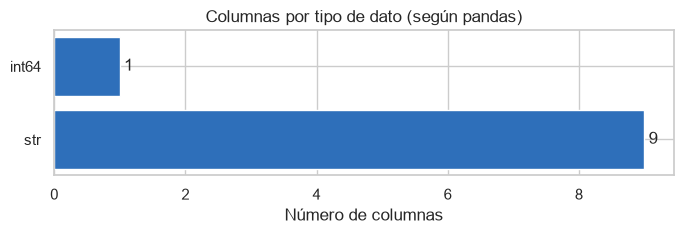

In [5]:
resumen_tipos = tipos["tipo_pandas"].value_counts()
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.barh(resumen_tipos.index, resumen_tipos.values, color=COLOR)
ax.set_title("Columnas por tipo de dato (según pandas)")
ax.set_xlabel("Número de columnas")
ax.bar_label(ax.containers[0], padding=3)
plt.tight_layout(); plt.show()

## 4. Análisis de nulos
Contamos dos tipos de nulos:
- **Nulos reales** (`NaN` / celda vacía).
- **Nulos ocultos**: textos como `"Not Given"`, `"N/A"` o `"?"` que en realidad significan "sin dato".
  La lista está en `transform.null_values` del config.

In [6]:
null_tokens = {v.strip().lower() for v in config["transform"]["null_values"]}


def nulos_ocultos(s: pd.Series) -> int:
    if not (pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s)):
        return 0
    return int(s.dropna().astype(str).str.strip().str.lower().isin(null_tokens).sum())


nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "nulos_ocultos": [nulos_ocultos(df[c]) for c in df.columns],
})
nulos["total_faltantes"] = nulos["nulos"] + nulos["nulos_ocultos"]
nulos["pct_total"] = (nulos["total_faltantes"] / len(df) * 100).round(2)
nulos = nulos.sort_values("pct_total", ascending=False)

print(f"Nulos reales (lo que reporta pandas): {int(df.isna().sum().sum()):,}")
print(f"Nulos ocultos en texto:               {int(nulos['nulos_ocultos'].sum()):,}")
print(f"Filas con al menos un faltante:       "
      f"{int((df.isna() | df.apply(lambda s: s.astype(str).str.strip().str.lower().isin(null_tokens))).any(axis=1).sum()):,}")
nulos

Nulos reales (lo que reporta pandas): 0
Nulos ocultos en texto:               2,875
Filas con al menos un faltante:       2,875


,nulos,pct_nulos,nulos_ocultos,total_faltantes,pct_total
director,0,0.00,2588,2588,29.44
country,0,0.00,287,287,3.27
type,0,0.00,0,0,0.00
show_id,0,0.00,0,0,0.00
title,0,0.00,0,0,0.00
date_added,0,0.00,0,0,0.00
release_year,0,0.00,0,0,0.00
rating,0,0.00,0,0,0.00
duration,0,0.00,0,0,0.00
listed_in,0,0.00,0,0,0.00


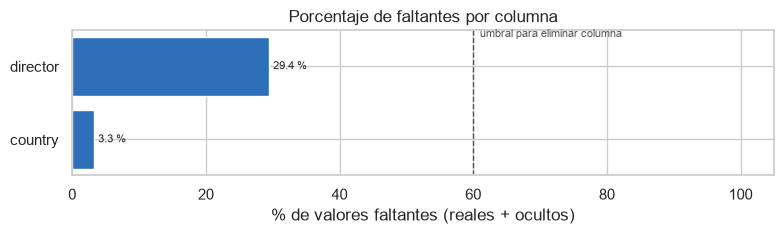

In [7]:
# Porcentaje de faltantes por columna
con_nulos = nulos[nulos["pct_total"] > 0]
if con_nulos.empty:
    print("No hay valores faltantes")
else:
    umbral = config["transform"]["drop_columns_null_pct"]
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(con_nulos) + 1.6))
    ax.barh(con_nulos.index[::-1], con_nulos["pct_total"][::-1], color=COLOR)
    ax.axvline(umbral, color="#555", ls="--", lw=1)
    ax.text(umbral + 1, len(con_nulos) - 0.6, "umbral para eliminar columna", fontsize=8, color="#555")
    ax.bar_label(ax.containers[0], fmt="%.1f %%", padding=3, fontsize=8)
    ax.set_xlabel("% de valores faltantes (reales + ocultos)")
    ax.set_title("Porcentaje de faltantes por columna")
    ax.set_xlim(0, 105)
    plt.tight_layout(); plt.show()

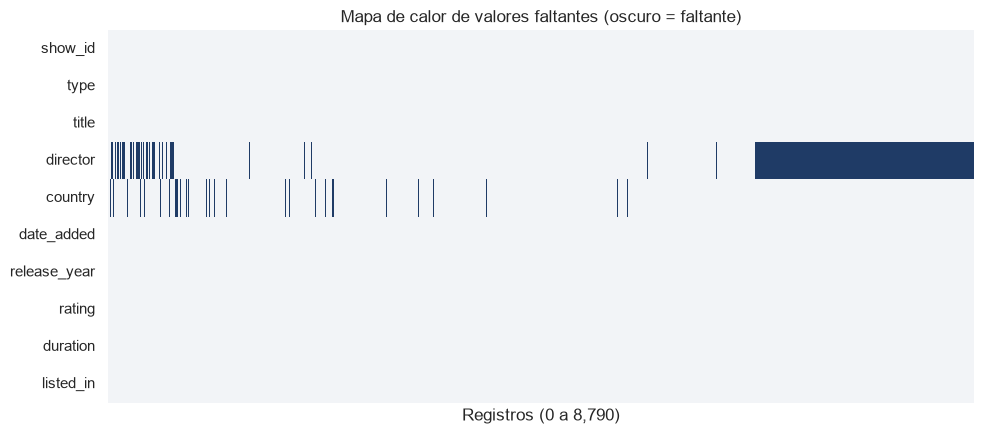

In [8]:
# Mapa de calor de faltantes: cada columna vertical es un registro; oscuro = faltante
mapa = df.isna() | df.apply(lambda s: s.astype(str).str.strip().str.lower().isin(null_tokens))
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(mapa.T, cbar=False, cmap=["#F2F4F7", "#1F3B66"], ax=ax, xticklabels=False)
ax.set_title("Mapa de calor de valores faltantes (oscuro = faltante)")
ax.set_xlabel(f"Registros (0 a {len(df):,})")
plt.tight_layout(); plt.show()

## 5. Calidad: duplicados y valores únicos

In [9]:
dup_exactos = int(df.duplicated().sum())
print(f"Registros duplicados exactos: {dup_exactos:,} ({dup_exactos / len(df) * 100:.2f} %)")
print(f"Registros únicos:             {len(df) - dup_exactos:,}")

# Las llaves del config están en snake_case: buscamos la columna original equivalente
mapa_cols = {to_snake_case(c): c for c in df.columns}

pk_orig = [mapa_cols[k] for k in config["transform"].get("primary_key", []) if k in mapa_cols]
if pk_orig:
    print(f"Duplicados por llave técnica {pk_orig}: {int(df.duplicated(subset=pk_orig).sum()):,}")

bk_orig = [mapa_cols[k] for k in config["transform"].get("business_key", []) if k in mapa_cols]
dup_bk = 0
if bk_orig:
    # Se comparan los textos sin espacios al inicio/final, igual que hace el pipeline
    df_bk = df[bk_orig].apply(lambda s: s.str.strip() if s.dtype != "int64" and s.dtype != "float64" else s)
    dup_bk_sin_limpiar = int(df.duplicated(subset=bk_orig).sum())
    dup_bk = int(df_bk.duplicated().sum())
    print(f"Duplicados por llave de negocio {bk_orig}: {dup_bk:,}  <- mismo contenido con distinto ID")
    if dup_bk > dup_bk_sin_limpiar:
        print(f"   ({dup_bk - dup_bk_sin_limpiar} solo aparecen al quitar espacios sobrantes del texto)")
    display(df[df_bk.duplicated(keep=False)].sort_values(bk_orig))

Registros duplicados exactos: 0 (0.00 %)
Registros únicos:             8,790
Duplicados por llave técnica ['show_id']: 0
Duplicados por llave de negocio ['type', 'title', 'director', 'release_year']: 4  <- mismo contenido con distinto ID
   (1 solo aparecen al quitar espacios sobrantes del texto)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
2925,s3963,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
4261,s5967,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
3285,s4523,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4260,s5966,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
2590,s3372,Movie,Consequences,Ozan Açıktan,Turkey,10/25/2019,2014,TV-MA,106 min,"Dramas, International Movies, Thrillers"
4718,s6530,Movie,Consequences,Ozan Açıktan,Turkey,10/25/2019,2014,TV-MA,106 min,"Dramas, International Movies, Thrillers"
393,s3997,TV Show,9-Feb,Not Given,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
537,s5965,TV Show,9-Feb,Not Given,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"


In [10]:
cardinalidad = pd.DataFrame({
    "valores_unicos": df.nunique(),
    "pct_unicos": (df.nunique() / len(df) * 100).round(2),
    "valor_mas_frecuente": [df[c].mode().iloc[0] if df[c].notna().any() else None for c in df.columns],
    "frecuencia_moda": [df[c].value_counts().iloc[0] if df[c].notna().any() else 0 for c in df.columns],
}).sort_values("valores_unicos", ascending=False)
cardinalidad["observacion"] = np.select(
    [cardinalidad["valores_unicos"] <= 1, cardinalidad["pct_unicos"] >= 95, cardinalidad["valores_unicos"] <= 20],
    ["constante o vacía -> eliminar", "posible identificador", "categórica"], default="")
cardinalidad

,valores_unicos,pct_unicos,valor_mas_frecuente,frecuencia_moda,observacion
show_id,8790,100.00,s1,1,posible identificador
title,8787,99.97,15-Aug,2,posible identificador
director,4528,51.51,Not Given,2588,
date_added,1713,19.49,1/1/2020,110,
listed_in,513,5.84,"Dramas, International Movies",362,
duration,220,2.50,1 Season,1791,
country,86,0.98,United States,3240,
release_year,74,0.84,2018,1146,
rating,14,0.16,TV-MA,3205,categórica
type,2,0.02,Movie,6126,categórica


### 5.1 Inconsistencias de texto en columnas categóricas
Variantes como `"BOGOTA"`, `"Bogotá"` y `" bogota "` cuentan como categorías distintas.

In [11]:
cat_cols = [c for c in df.columns
            if (pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c]))
            and df[c].nunique() <= 100 and tipos.loc[c, "patron"] == ""]
encontradas = False
for c in cat_cols:
    vals = df[c].dropna().astype(str)
    normal = vals.str.strip().map(lambda v: strip_accents(v).lower())
    if normal.nunique() < vals.nunique():
        encontradas = True
        print(f"{c}: {vals.nunique()} variantes escritas -> {normal.nunique()} categorías reales")
if not encontradas:
    print("No se encontraron variantes de escritura en las columnas categóricas:", cat_cols)

No se encontraron variantes de escritura en las columnas categóricas: ['type', 'country', 'rating']


## 6. Estadística descriptiva

In [12]:
# Convertimos temporalmente columnas numéricas guardadas como texto para poder describirlas
df_num = df.copy()
for c in df_num.columns:
    ts = tipos.loc[c, "tipo_sugerido"]
    if "guardado como texto" in ts:
        df_num[c] = pd.to_numeric(df_num[c].astype(str).str.strip(), errors="coerce")

num_cols = [c for c in df_num.select_dtypes("number").columns
            if df_num[c].notna().any() and df_num[c].nunique() > 1]
desc = df_num[num_cols].describe().T
desc["asimetria"] = df_num[num_cols].skew()
desc["curtosis"] = df_num[num_cols].kurt()
desc

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
release_year,"8,790.00","2,014.18",8.83,"1,925.00","2,013.00","2,017.00","2,019.00","2,021.00",-3.45,16.22


In [13]:
texto_cols = [c for c in df.columns if pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c])]
df[texto_cols].describe().T

,count,unique,top,freq
show_id,8790,8790,s1,1
type,8790,2,Movie,6126
title,8790,8787,9-Feb,2
director,8790,4528,Not Given,2588
country,8790,86,United States,3240
date_added,8790,1713,1/1/2020,110
rating,8790,14,TV-MA,3205
duration,8790,220,1 Season,1791
listed_in,8790,513,"Dramas, International Movies",362


## 7. Visualizaciones
### 7.1 Distribuciones (histogramas)
Muestran la forma de cada variable numérica: simetría, sesgo y valores raros.

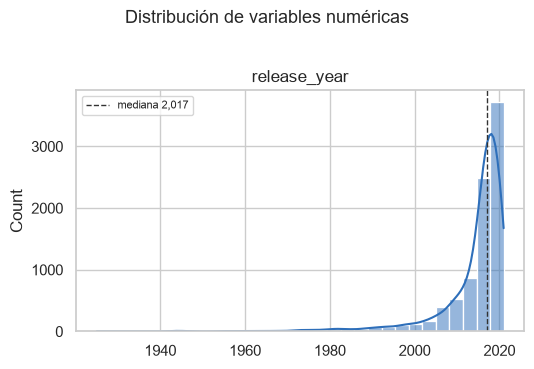

In [14]:
# Excluimos identificadores: enteros con un valor distinto por fila o columnas llamadas "id"
def es_identificador(s):
    nn = s.dropna()
    return ((nn % 1 == 0).all() and nn.nunique() == len(nn)) or "id" in to_snake_case(s.name).split("_")


num_plot = [c for c in num_cols if not es_identificador(df_num[c])]
n = len(num_plot)
ncols = min(3, max(n, 1))
nrows = int(np.ceil(n / ncols)) or 1
fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.6 * nrows), squeeze=False)
axes = axes.ravel()
for ax, c in zip(axes, num_plot):
    datos = df_num[c].dropna()
    discreta = datos.nunique() <= 15
    sns.histplot(datos, bins=30, discrete=discreta, kde=not discreta, color=COLOR, ax=ax,
                 edgecolor="white", shrink=0.8 if discreta else 1)
    ax.axvline(datos.median(), color="#333", ls="--", lw=1, label=f"mediana {datos.median():,.0f}")
    ax.set_title(c); ax.set_xlabel(""); ax.legend(fontsize=8)
for ax in axes[n:]:
    ax.set_visible(False)
fig.suptitle("Distribución de variables numéricas", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

### 7.2 Diagramas de caja (outliers)
Un punto fuera de los "bigotes" está más allá de **1.5 × IQR** (rango intercuartílico) y es candidato a outlier.

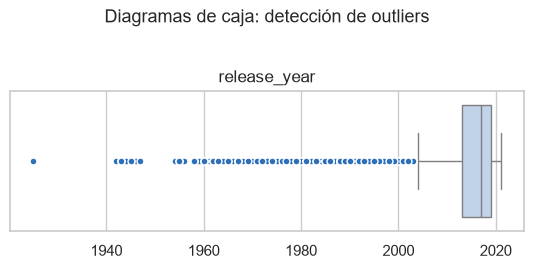

In [15]:
fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 2.6 * nrows), squeeze=False)
axes = axes.ravel()
for ax, c in zip(axes, num_plot):
    sns.boxplot(x=df_num[c], ax=ax, color="#BBD3EE", linewidth=1,
                flierprops=dict(marker="o", markersize=5, markerfacecolor=COLOR, markeredgecolor="white"))
    ax.set_title(c); ax.set_xlabel("")
for ax in axes[n:]:
    ax.set_visible(False)
fig.suptitle("Diagramas de caja: detección de outliers", y=1.03, fontsize=13)
plt.tight_layout(); plt.show()

In [16]:
def resumen_outliers(s, k=1.5):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    n_out = int(((s < lo) | (s > hi)).sum())
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "lim_inf": lo, "lim_sup": hi,
                      "outliers": n_out, "pct_outliers": n_out / len(s) * 100, "min": s.min(), "max": s.max()})


outliers = pd.DataFrame({c: resumen_outliers(df_num[c]) for c in num_plot}).T
outliers.sort_values("pct_outliers", ascending=False)

,Q1,Q3,IQR,lim_inf,lim_sup,outliers,pct_outliers,min,max
release_year,"2,013.00","2,019.00",6.00,"2,004.00","2,028.00",717.00,8.16,"1,925.00","2,021.00"


### 7.3 Variables categóricas (frecuencias)

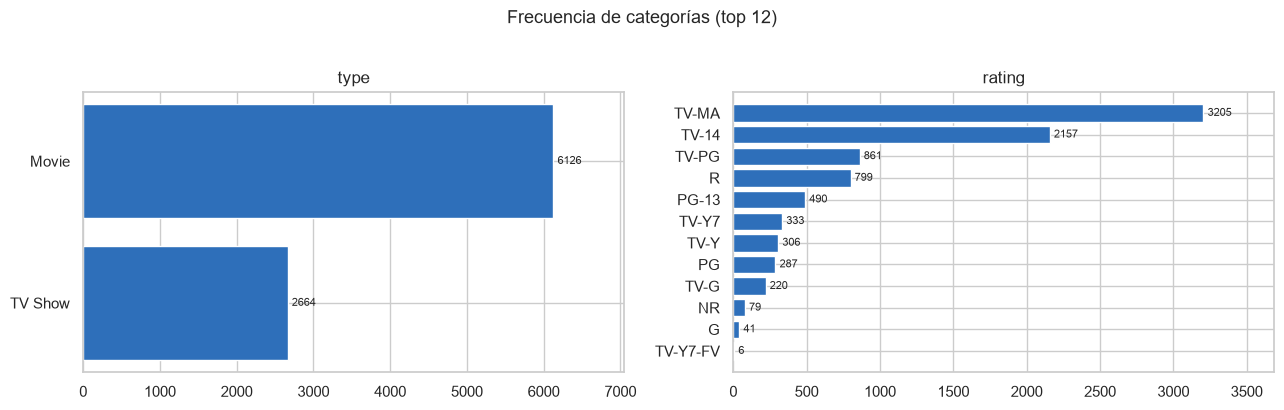

In [17]:
cat_plot = [c for c in cat_cols if 1 < df[c].nunique() <= 30]
if cat_plot:
    nc = min(2, len(cat_plot)); nr = int(np.ceil(len(cat_plot) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(6.5 * nc, 4 * nr), squeeze=False)
    axes = axes.ravel()
    for ax, c in zip(axes, cat_plot):
        vc = df[c].fillna("(nulo)").astype(str).value_counts().head(12)
        ax.barh(vc.index[::-1], vc.values[::-1], color=COLOR)
        ax.bar_label(ax.containers[0], padding=3, fontsize=8)
        ax.set_title(c); ax.margins(x=0.15)
    for ax in axes[len(cat_plot):]:
        ax.set_visible(False)
    fig.suptitle("Frecuencia de categorías (top 12)", y=1.02, fontsize=13)
    plt.tight_layout(); plt.show()

### 7.4 Correlaciones entre variables numéricas
Azul = relación positiva, rojo = negativa, blanco = sin relación. Requiere al menos 2 variables numéricas.

In [18]:
corr_cols = [c for c in num_plot if df_num[c].nunique() > 2]
if len(corr_cols) >= 2:
    corr = df_num[corr_cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    lado = min(1 + 0.9 * len(corr_cols), 9)
    fig, ax = plt.subplots(figsize=(lado + 1.5, lado))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1,
                linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title("Matriz de correlación (Pearson)")
    plt.tight_layout(); plt.show()
else:
    print(f"Solo hay {len(corr_cols)} variable(s) numérica(s) en el archivo original: {corr_cols}.")
    print("La correlación se podrá calcular en silver, cuando duration se convierta en número (ver 7.6).")

Solo hay 1 variable(s) numérica(s) en el archivo original: ['release_year'].
La correlación se podrá calcular en silver, cuando duration se convierta en número (ver 7.6).


### 7.5 Comportamiento en el tiempo (columnas de fecha)

date_added: rango 2008-01-01 -> 2021-09-25 | fechas no válidas: 0


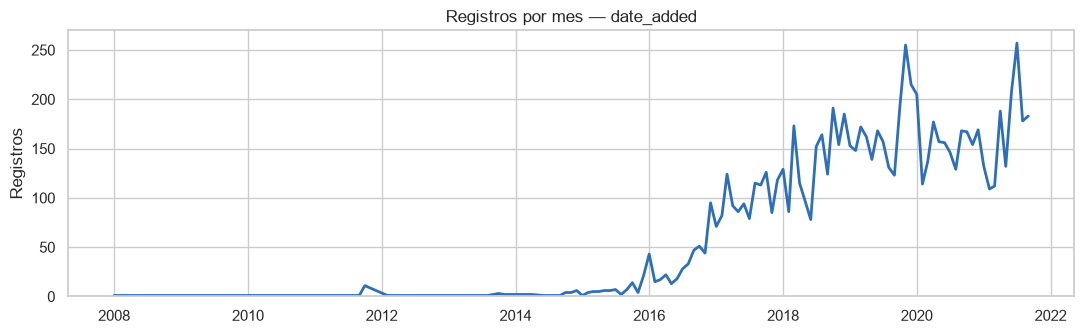

In [19]:
fecha_cols = [c for c in df.columns if "fecha" in tipos.loc[c, "tipo_sugerido"]]
for c in fecha_cols:
    fechas = pd.to_datetime(df[c], errors="coerce", format="mixed")
    invalidas = int(fechas.isna().sum() - df[c].isna().sum())
    print(f"{c}: rango {fechas.min():%Y-%m-%d} -> {fechas.max():%Y-%m-%d} | fechas no válidas: {invalidas}")
    serie = fechas.dropna().dt.to_period("M").value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(serie.index.to_timestamp(), serie.values, color=COLOR, lw=2)
    ax.set_title(f"Registros por mes — {c}"); ax.set_ylabel("Registros"); ax.set_ylim(0)
    plt.tight_layout(); plt.show()
if not fecha_cols:
    print("No se detectaron columnas de fecha.")

### 7.6 Análisis específico del dataset Netflix


In [20]:
# Columnas auxiliares solo para el análisis (no modifican el archivo original)
nf = df.copy()
for c in ["director", "country"]:
    nf[c] = nf[c].replace("Not Given", np.nan)
nf["fecha_ingreso"] = pd.to_datetime(nf["date_added"], format="%m/%d/%Y", errors="coerce")
nf["anio_ingreso"] = nf["fecha_ingreso"].dt.year
nf["duracion_valor"] = nf["duration"].str.extract(r"(\d+)")[0].astype(float)
nf["duracion_unidad"] = np.where(nf["duration"].str.contains("min"), "minutos", "temporadas")

print("Unidades de 'duration' por tipo de contenido:")
pd.crosstab(nf["type"], nf["duracion_unidad"])

Unidades de 'duration' por tipo de contenido:


duracion_unidad,minutos,temporadas
type,,
Movie,6126,0
TV Show,0,2664


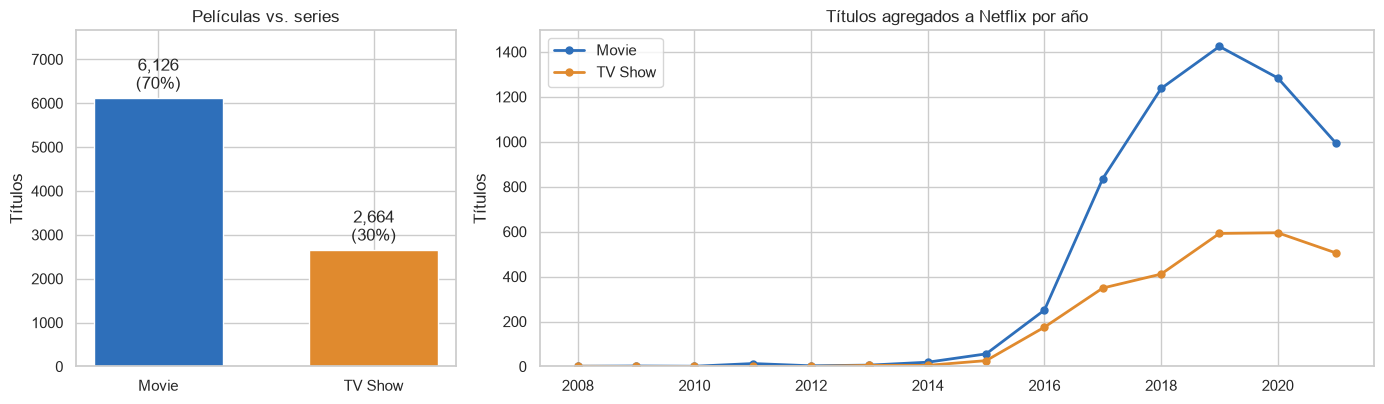

Nota: 2021 está incompleto (el dataset llega hasta 2021-09-25)


In [21]:
# Películas vs. series y contenido agregado por año
TIPO_COLOR = {"Movie": "#2E6FBA", "TV Show": "#E08A2E"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})

vc = nf["type"].value_counts()
ax1.bar(vc.index, vc.values, color=[TIPO_COLOR[t] for t in vc.index], width=0.6)
ax1.bar_label(ax1.containers[0], labels=[f"{v:,}\n({v / len(nf):.0%})" for v in vc.values], padding=3)
ax1.set_title("Películas vs. series"); ax1.set_ylabel("Títulos"); ax1.margins(y=0.25)

por_anio = nf.groupby(["anio_ingreso", "type"]).size().unstack(fill_value=0)
for t in por_anio.columns:
    ax2.plot(por_anio.index, por_anio[t], color=TIPO_COLOR[t], lw=2, marker="o", markersize=5, label=t)
ax2.set_title("Títulos agregados a Netflix por año"); ax2.set_ylabel("Títulos"); ax2.set_ylim(0)
ax2.legend(loc="upper left")
plt.tight_layout(); plt.show()
print("Nota: 2021 está incompleto (el dataset llega hasta", nf["fecha_ingreso"].max().strftime("%Y-%m-%d") + ")")

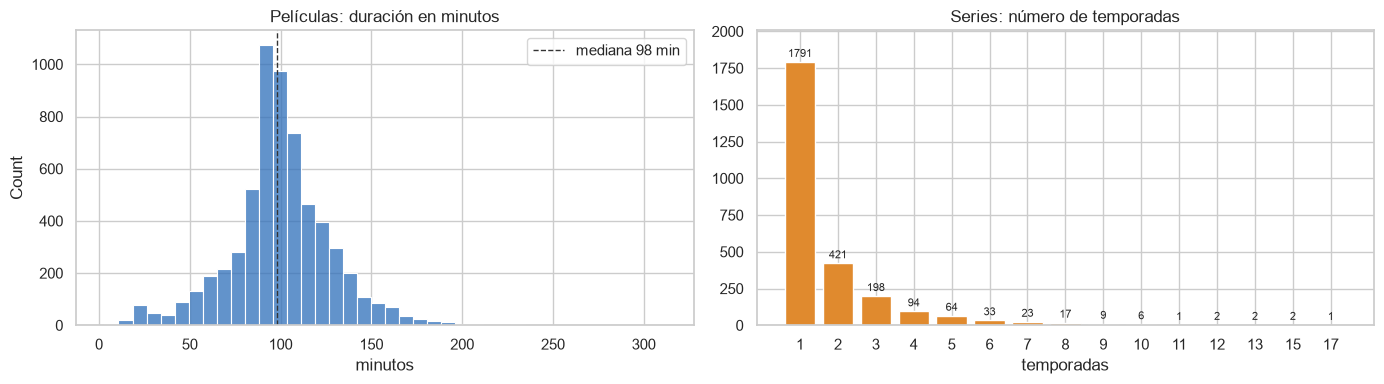

Películas: 3–312 min | Series: 1–17 temporadas


,Q1,Q3,IQR,lim_inf,lim_sup,outliers,pct_outliers,min,max
películas (min),87.00,114.00,27.00,46.50,154.50,449.00,7.33,3.00,312.00
series (temporadas),1.00,2.00,1.00,-0.50,3.50,254.00,9.53,1.00,17.00


In [22]:
# Duración: cada tipo en su propia unidad (mezclarlas daría estadísticas sin sentido)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pel = nf.loc[nf["duracion_unidad"] == "minutos", "duracion_valor"]
ser = nf.loc[nf["duracion_unidad"] == "temporadas", "duracion_valor"]

sns.histplot(pel, bins=40, color=TIPO_COLOR["Movie"], edgecolor="white", ax=axes[0])
axes[0].axvline(pel.median(), color="#333", ls="--", lw=1, label=f"mediana {pel.median():.0f} min")
axes[0].set_title("Películas: duración en minutos"); axes[0].set_xlabel("minutos"); axes[0].legend()

vc = ser.value_counts().sort_index()
axes[1].bar(vc.index.astype(int).astype(str), vc.values, color=TIPO_COLOR["TV Show"])
axes[1].bar_label(axes[1].containers[0], padding=2, fontsize=8)
axes[1].set_title("Series: número de temporadas"); axes[1].set_xlabel("temporadas"); axes[1].margins(y=0.12)
plt.tight_layout(); plt.show()

print(f"Películas: {pel.min():.0f}–{pel.max():.0f} min | Series: {ser.min():.0f}–{ser.max():.0f} temporadas")
pd.DataFrame({"películas (min)": resumen_outliers(pel), "series (temporadas)": resumen_outliers(ser)}).T

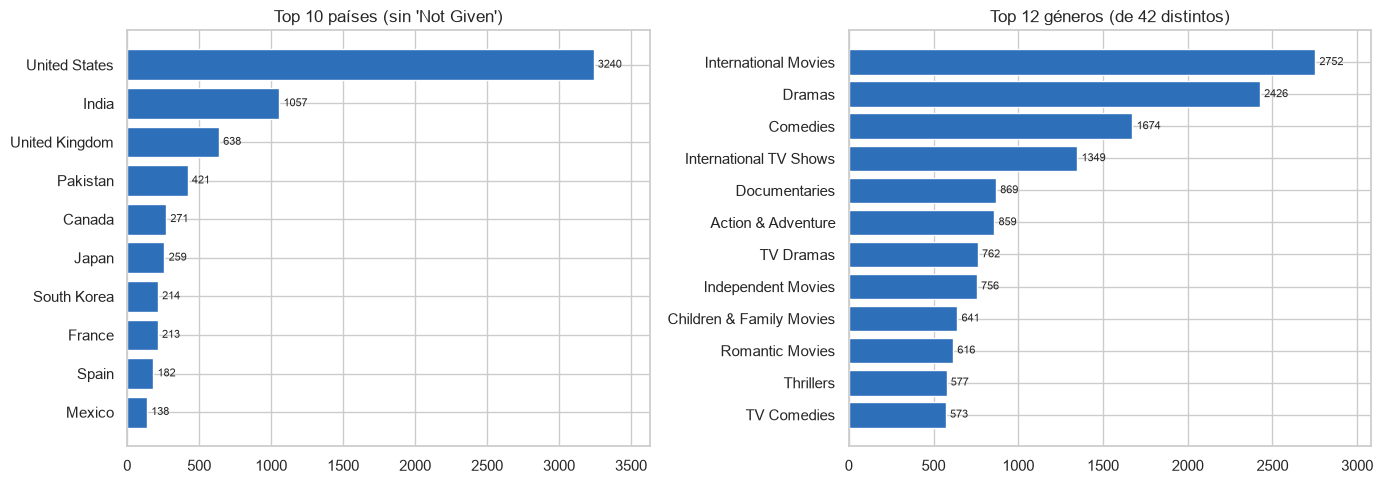

Géneros por título: {1: 2012, 2: 3052, 3: 3726}


In [23]:
# Top países y géneros. 'listed_in' tiene varios géneros por celda: se separan con explode()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

paises = nf["country"].value_counts().head(10)
axes[0].barh(paises.index[::-1], paises.values[::-1], color=COLOR)
axes[0].bar_label(axes[0].containers[0], padding=3, fontsize=8)
axes[0].set_title("Top 10 países (sin 'Not Given')"); axes[0].margins(x=0.12)

generos = nf["listed_in"].str.split(", ").explode().str.strip()
top_g = generos.value_counts().head(12)
axes[1].barh(top_g.index[::-1], top_g.values[::-1], color=COLOR)
axes[1].bar_label(axes[1].containers[0], padding=3, fontsize=8)
axes[1].set_title(f"Top 12 géneros (de {generos.nunique()} distintos)"); axes[1].margins(x=0.12)
plt.tight_layout(); plt.show()

print("Géneros por título:", nf["listed_in"].str.split(", ").str.len().value_counts().sort_index().to_dict())

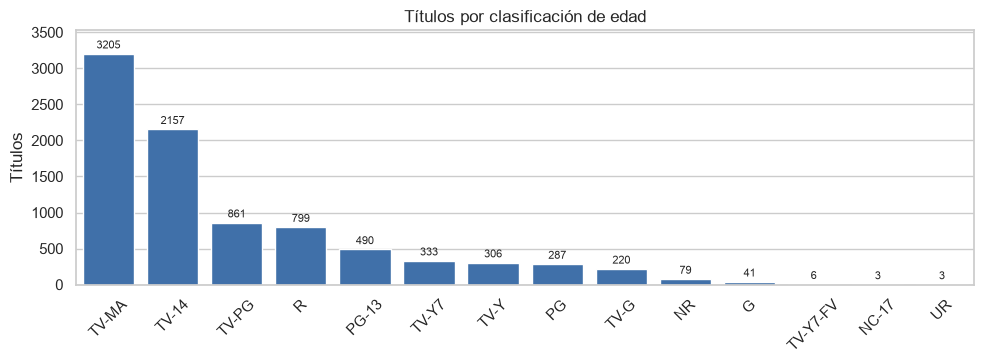

In [24]:
# Clasificación por edad (rating)
orden = nf["rating"].value_counts().index
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.countplot(data=nf, x="rating", order=orden, color=COLOR, ax=ax)
ax.bar_label(ax.containers[0], padding=2, fontsize=8)
ax.set_title("Títulos por clasificación de edad"); ax.set_xlabel(""); ax.set_ylabel("Títulos")
ax.margins(y=0.1); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

#### Controles de consistencia
Problemas que no aparecen en los conteos de nulos ni de duplicados.

In [25]:
# 1) Año de lanzamiento posterior al año en que se agregó a Netflix (imposible)
inconsistentes = nf[nf["release_year"] > nf["anio_ingreso"]]
print(f"1) Lanzamiento posterior al ingreso a Netflix: {len(inconsistentes)} títulos")
display(inconsistentes[["show_id", "title", "type", "release_year", "date_added"]])

1) Lanzamiento posterior al ingreso a Netflix: 14 títulos


,show_id,title,type,release_year,date_added
3869,s5395,Hans Teeuwen: Real Rancour,Movie,2018,7/1/2017
5138,s7064,Incoming,Movie,2019,10/26/2018
5178,s7113,Jack Taylor,TV Show,2016,3/31/2013
6948,s1552,Hilda,TV Show,2021,12/14/2020
6992,s1697,Polly Pocket,TV Show,2021,11/15/2020
7355,s2921,Love Is Blind,TV Show,2021,2/13/2020
7436,s3169,Fuller House,TV Show,2020,12/6/2019
7484,s3288,Maradona in Mexico,TV Show,2020,11/13/2019
7517,s3370,BoJack Horseman,TV Show,2020,10/25/2019
7537,s3434,The Hook Up Plan,TV Show,2020,10/11/2019


In [26]:
# 2) Títulos que Excel convirtió en fechas (ej. '9-Feb')
titulos_fecha = nf[nf["title"].astype(str).str.match(r"^\d{1,2}-[A-Z][a-z]{2}$")]
print(f"2) Títulos con forma de fecha (posible corrupción por Excel): {len(titulos_fecha)}")
display(titulos_fecha[["show_id", "title", "type", "release_year", "director"]])

# 3) Espacios sobrantes en textos
espacios = {c: int((df[c].dropna().astype(str) != df[c].dropna().astype(str).str.strip()).sum()) for c in texto_cols}
print("3) Celdas con espacios al inicio o al final:", {k: v for k, v in espacios.items() if v})
display(df[df["title"] != df["title"].str.strip()][["show_id", "title", "release_year"]].assign(
    title_visible=lambda d: "'" + d["title"] + "'"))

2) Títulos con forma de fecha (posible corrupción por Excel): 7


,show_id,title,type,release_year,director
393,s3997,9-Feb,TV Show,2018,NaN
537,s5965,9-Feb,TV Show,2018,NaN
2925,s3963,15-Aug,Movie,2019,Swapnaneel Jayakar
3285,s4523,22-Jul,Movie,2018,Paul Greengrass
4259,s5964,1-Oct,Movie,2014,Kunle Afolayan
4260,s5966,22-Jul,Movie,2018,Paul Greengrass
4261,s5967,15-Aug,Movie,2019,Swapnaneel Jayakar


3) Celdas con espacios al inicio o al final: {'title': 1}


,show_id,title,release_year,title_visible
4718,s6530,Consequences,2014,'Consequences '


## 8. Hallazgos y reglas para la capa silver
La siguiente celda resume automáticamente los problemas encontrados. Úsala para ajustar
la sección `transform` de `config/config.yaml`.

In [27]:
hallazgos = [f"Dataset de {filas:,} filas x {columnas} columnas."]
if dup_exactos:
    hallazgos.append(f"{dup_exactos} duplicados exactos -> se eliminan.")
if dup_bk:
    hallazgos.append(f"{dup_bk} duplicados por llave de negocio {bk_orig} -> se eliminan.")
for c, r in nulos[nulos["pct_total"] > 0].iterrows():
    ts = tipos.loc[c, "tipo_sugerido"]
    if r["pct_total"] > config["transform"]["drop_columns_null_pct"]:
        accion = "eliminar columna"
    elif "fecha" in ts:
        accion = "dejar nula (no se inventan fechas)"
    elif "entero" in ts or "decimal" in ts:
        accion = "imputar con la mediana"
    else:
        accion = f"imputar con '{config['transform']['impute'].get('unknown_label', 'Desconocido')}'"
    oculto = f" (todos ocultos: {int(r['nulos_ocultos'])})" if r["nulos"] == 0 and r["nulos_ocultos"] else ""
    hallazgos.append(f"'{c}': {r['pct_total']:.1f} % faltantes{oculto} -> {accion}.")
for c, r in tipos[tipos["tipo_sugerido"].str.contains("guardad")].iterrows():
    hallazgos.append(f"'{c}' es {r['tipo_pandas']} pero contiene {r['tipo_sugerido']} -> corregir tipo.")
for c, r in tipos[tipos["patron"] != ""].iterrows():
    accion = "separar en valor numérico + unidad" if r["patron"] == "valor + unidad" else "extraer valor principal y cantidad"
    hallazgos.append(f"'{c}' es {r['patron']} -> {accion}.")
for c, r in outliers[outliers["outliers"] > 0].iterrows():
    hallazgos.append(f"'{c}': {int(r['outliers'])} outliers ({r['pct_outliers']:.1f} %), rango normal "
                     f"[{r['lim_inf']:,.0f}, {r['lim_sup']:,.0f}] -> marcar, no eliminar.")
if "inconsistentes" in globals() and len(inconsistentes):
    hallazgos.append(f"{len(inconsistentes)} títulos con lanzamiento posterior a su ingreso -> marcar con regla de negocio.")

for i, h in enumerate(hallazgos, 1):
    print(f"{i:>2}. {h}")

 1. Dataset de 8,790 filas x 10 columnas.
 2. 4 duplicados por llave de negocio ['type', 'title', 'director', 'release_year'] -> se eliminan.
 3. 'director': 29.4 % faltantes (todos ocultos: 2588) -> imputar con 'Desconocido'.
 4. 'country': 3.3 % faltantes (todos ocultos: 287) -> imputar con 'Desconocido'.
 5. 'date_added' es str pero contiene fecha (guardada como texto) -> corregir tipo.
 6. 'duration' es valor + unidad -> separar en valor numérico + unidad.
 7. 'listed_in' es multivalor -> extraer valor principal y cantidad.
 8. 'release_year': 717 outliers (8.2 %), rango normal [2,004, 2,028] -> marcar, no eliminar.
 9. 14 títulos con lanzamiento posterior a su ingreso -> marcar con regla de negocio.


**Decisiones tomadas para Netflix** (ya configuradas en `config/config.yaml`):

| Hallazgo del EDA | Regla en silver |
|---|---|
| Pandas reporta 0 nulos, pero `"Not Given"` aparece en `director` (29 %) y `country` (3 %) | `"Not Given"` va a `null_values` y se imputa como `"Desconocido"`. No se usa la moda: inventaría directores |
| 0 duplicados exactos, pero 4 contenidos aparecen dos veces con distinto `show_id` (uno de ellos, *Consequences*, solo se detecta al quitar un espacio al final del título) | Se limpian espacios y se usa `business_key: [type, title, director, release_year]` |
| `date_added` es texto (`9/25/2021`) | Fecha con formato `%m/%d/%Y`; se derivan `date_added_anio` y `date_added_mes` |
| `duration` mezcla `"90 min"` con `"2 Seasons"` | Se separa en `duration_valor` (entero) y `duration_unidad` (minutos / temporadas) |
| `listed_in` tiene hasta 3 géneros por celda | Se crean `listed_in_principal` y `listed_in_cantidad`; la original se conserva para *explode* en gold |
| Duraciones atípicas, cada unidad con su escala | Outliers IQR **por unidad**, solo marcados en `duration_valor_es_outlier` |
| Películas muy antiguas (desde 1925) | Se marcan como outlier en `release_year_es_outlier`, no se eliminan: son contenido real |
| 14 títulos con lanzamiento posterior a su ingreso | Regla de negocio: columna `lanzamiento_posterior_a_ingreso` |
| `rating` usa siglas (`TV-MA`) | `title_case: false` para no convertirlas en `Tv-Ma` |
| Títulos convertidos en fecha por Excel (`9-Feb`) | Se documenta; el título real no se puede recuperar desde este archivo |

## 9. Verificación: original vs. silver
Ejecuta `python main.py` en la terminal y luego esta celda para comprobar el efecto de la limpieza.

In [28]:
name = config["output"]["dataset_name"]; fmt = config["output"]["format"]
silver_path = resolve_path(config["paths"]["silver"]) / f"{name}_silver.{fmt}"

if silver_path.exists():
    silver = pd.read_parquet(silver_path) if fmt == "parquet" else pd.read_csv(silver_path)
    data_cols = [c for c in silver.columns if not c.startswith("_")]
    comparacion = pd.DataFrame({
        "original": [len(df), df.shape[1], int(nulos["total_faltantes"].sum()), dup_exactos + dup_bk],
        "silver": [len(silver), len(data_cols), int(silver[data_cols].isna().sum().sum()),
                   int(silver[data_cols].duplicated().sum())],
    }, index=["filas", "columnas de datos", "celdas faltantes (reales + ocultas)", "duplicados (exactos + negocio)"])
    display(comparacion)
    display(silver.dtypes.to_frame("tipo_silver"))
    display(silver.head())
else:
    print("Aún no existe la capa silver. Ejecuta: python main.py")

,original,silver
filas,8790,8786
columnas de datos,10,18
celdas faltantes (reales + ocultas),2875,0
duplicados (exactos + negocio),4,0


,tipo_silver
show_id,string
type,category
title,string
director,string
country,category
date_added,datetime64[us]
release_year,Int64
rating,category
listed_in,string
_source_file,str


,show_id,type,title,director,country,date_added,release_year,rating,listed_in,_source_file,_ingestion_ts,duration_valor,duration_unidad,listed_in_principal,listed_in_cantidad,date_added_anio,date_added_mes,duration_valor_es_outlier,release_year_es_outlier,lanzamiento_posterior_a_ingreso,_processed_ts
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,Documentaries,netflix1.csv,2026-10-09 14:00:08,90,minutos,Documentaries,1,2021,9,False,False,False,2026-10-09 14:00:09
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",netflix1.csv,2026-10-09 14:00:08,1,temporadas,Crime TV Shows,3,2021,9,False,False,False,2026-10-09 14:00:09
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,"TV Dramas, TV Horror, TV Mysteries",netflix1.csv,2026-10-09 14:00:08,1,temporadas,TV Dramas,3,2021,9,False,False,False,2026-10-09 14:00:09
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,"Children & Family Movies, Comedies",netflix1.csv,2026-10-09 14:00:08,91,minutos,Children & Family Movies,2,2021,9,False,False,False,2026-10-09 14:00:09
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,"Dramas, Independent Movies, International Movies",netflix1.csv,2026-10-09 14:00:08,125,minutos,Dramas,3,2021,9,False,True,False,2026-10-09 14:00:09


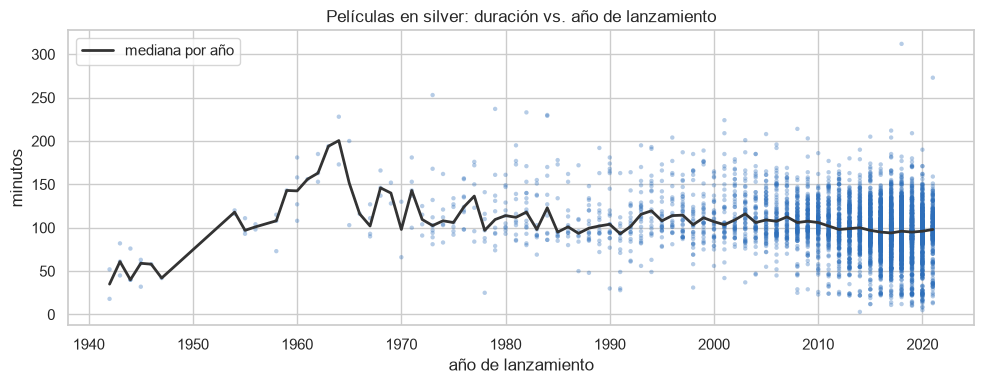

Correlación de Pearson (año vs. duración de películas): -0.21


In [29]:
# Ahora que duration es numérica, ya se puede relacionar con el año de lanzamiento
if silver_path.exists():
    pel_s = silver[silver["duration_unidad"] == "minutos"]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(pel_s["release_year"], pel_s["duration_valor"], s=10, alpha=0.35, color=COLOR, edgecolors="none")
    tendencia = pel_s.groupby("release_year")["duration_valor"].median()
    ax.plot(tendencia.index, tendencia.values, color="#333", lw=2, label="mediana por año")
    ax.set_title("Películas en silver: duración vs. año de lanzamiento")
    ax.set_xlabel("año de lanzamiento"); ax.set_ylabel("minutos"); ax.legend()
    plt.tight_layout(); plt.show()
    r = pel_s[["release_year", "duration_valor"]].astype(float).corr().iloc[0, 1]
    print(f"Correlación de Pearson (año vs. duración de películas): {r:.2f}")